# Cohort Purification — GSE282701 (Patient-Paired HBV⁺ & HBV⁻ HCC scRNA-seq)
 
**Accession:** NCBI GEO `GSE282701` (10x Genomics Chromium 3' scRNA-seq)  
**Biological Scope:** 12 patient-paired libraries from 6 hepatocellular carcinoma (HCC) donors (3 HBV⁺ [`P10, P12, P13`] and 3 HBV⁻ [`P11, P14, P15`], each providing matched `Tumor_Core` and `Adjacent_Liver` specimens; 141,603 raw barcodes; 125,967 singlets)  
**Pipeline Objective:** Two-tier mesenchymal extraction, reciprocal Z-score lineage exclusion and 4-group stratification by viral status and spatial tissue compartment.

In [ ]:
import os, glob, re, json, tarfile, gc, warnings
import numpy as np
import pandas as pd
import scipy.io
import scipy.sparse as spa
from sklearn.preprocessing import StandardScaler, RobustScaler
import anndata as ad
import scanpy as sc
import scrublet as scr
import matplotlib.pyplot as plt
import seaborn as sns

warnings.filterwarnings("ignore")
RANDOM_STATE = 0
np.random.seed(RANDOM_STATE)
sc.settings.verbosity = 1

In [ ]:
DATASET_ID  = "GSE282701" 
BASE_DIR    = f"./data/raw/{DATASET_ID}"
TAR_PATH    = os.path.join(BASE_DIR, f"{DATASET_ID}_RAW.tar")
RAW_DIR     = os.path.join(BASE_DIR, "raw_extracted")
OUT_DIR     = os.path.join(BASE_DIR, "results_v3")
FIG_DIR     = os.path.join(OUT_DIR, "figures")

os.makedirs(RAW_DIR, exist_ok=True)
os.makedirs(OUT_DIR, exist_ok=True)
os.makedirs(FIG_DIR, exist_ok=True)

if os.path.exists(TAR_PATH) and len(glob.glob(os.path.join(RAW_DIR, "*matrix.mtx.gz"))) == 0:
    with tarfile.open(TAR_PATH, "r") as tar:
        tar.extractall(path=RAW_DIR)


In [ ]:
matrix_paths = sorted(glob.glob(os.path.join(RAW_DIR, "*_matrix.mtx.gz")))

sample_to_patient = {
    "010": ("P10", "HBV_pos"),
    "011": ("P11", "HBV_neg"),
    "012": ("P12", "HBV_pos"),
    "013": ("P13", "HBV_pos"),
    "014": ("P14", "HBV_neg"),
    "015": ("P15", "HBV_neg"),
}

records = []
for mp in matrix_paths:
    base = os.path.basename(mp).replace("_matrix.mtx.gz", "")
    gsm = base.split("_")[0]
    code = base.split("_")[1]          # 010T, 010P
    num_code = code[:3]                # 010 .. 015
    tissue_flag = code[3:].upper()     # 'T' (Tumor) or 'P' (Paired Adjacent)
    patient_id, etiology = sample_to_patient.get(num_code, (f"P{num_code}", "Unknown"))
    
    records.append({
        "dataset_id": DATASET_ID,
        "sample_id": gsm,
        "sample_name": base,
        "patient_id": patient_id,
        "matrix_path": mp,
        "tissue": "Tumor" if tissue_flag == "T" else "Adjacent",
        "platform": "Illumina NovaSeq 6000",
        "batch": patient_id,
        "disease_group": "HCC",
        "disease": "HCC",
        "etiology": etiology
    })

meta_df = pd.DataFrame(records)
meta_liver = meta_df.copy() if INCLUDE_ADJACENT else meta_df[meta_df["tissue"] == "Tumor"].copy().reset_index(drop=True)
meta_liver.to_csv(os.path.join(OUT_DIR, f"{DATASET_ID}_sample_sheet.csv"), index=False)

rep_audit = meta_liver.groupby("etiology")["patient_id"].nunique().rename("n_donors")
print("BIOLOGICAL REPLICATE AUDIT (GSE282701)")
print(rep_audit.to_frame())
print(pd.crosstab(meta_liver["patient_id"], meta_liver["etiology"], margins=True))
meta_liver.head(12)

BIOLOGICAL REPLICATE AUDIT (GSE282701)
          n_donors
etiology          
HBV_neg          3
HBV_pos          3
etiology    HBV_neg  HBV_pos  All
patient_id                       
P10               0        2    2
P11               2        0    2
P12               0        2    2
P13               0        2    2
P14               2        0    2
P15               2        0    2
All               6        6   12


,dataset_id,sample_id,sample_name,patient_id,matrix_path,tissue,platform,batch,disease_group,disease,etiology
0,GSE282701,GSM8649020,GSM8649020_015T,P15,./data/raw/GSE282701...,Tumor,Illumina NovaSeq 6000,P15,HCC,HCC,HBV_neg
1,GSE282701,GSM8649021,GSM8649021_015P,P15,./data/raw/GSE282701...,Adjacent,Illumina NovaSeq 6000,P15,HCC,HCC,HBV_neg
2,GSE282701,GSM8649022,GSM8649022_014T,P14,./data/raw/GSE282701...,Tumor,Illumina NovaSeq 6000,P14,HCC,HCC,HBV_neg
3,GSE282701,GSM8649023,GSM8649023_014P,P14,./data/raw/GSE282701...,Adjacent,Illumina NovaSeq 6000,P14,HCC,HCC,HBV_neg
4,GSE282701,GSM8649024,GSM8649024_013T,P13,./data/raw/GSE282701...,Tumor,Illumina NovaSeq 6000,P13,HCC,HCC,HBV_pos
5,GSE282701,GSM8649025,GSM8649025_013P,P13,./data/raw/GSE282701...,Adjacent,Illumina NovaSeq 6000,P13,HCC,HCC,HBV_pos
6,GSE282701,GSM8649026,GSM8649026_012T,P12,./data/raw/GSE282701...,Tumor,Illumina NovaSeq 6000,P12,HCC,HCC,HBV_pos
7,GSE282701,GSM8649027,GSM8649027_012P,P12,./data/raw/GSE282701...,Adjacent,Illumina NovaSeq 6000,P12,HCC,HCC,HBV_pos
8,GSE282701,GSM8649028,GSM8649028_011T,P11,./data/raw/GSE282701...,Tumor,Illumina NovaSeq 6000,P11,HCC,HCC,HBV_neg
9,GSE282701,GSM8649029,GSM8649029_011P,P11,./data/raw/GSE282701...,Adjacent,Illumina NovaSeq 6000,P11,HCC,HCC,HBV_neg


In [4]:
def load_10x_triplet_282701(matrix_fp: str) -> ad.AnnData:
    base = matrix_fp.replace("_matrix.mtx.gz", "")
    features_fp = base + "_features.tsv.gz"
    if not os.path.exists(features_fp):
        features_fp = base + "_genes.tsv.gz"
    barcodes_fp = base + "_barcodes.tsv.gz"

    X = scipy.io.mmread(matrix_fp).T.tocsr().astype(np.float32)
    genes = pd.read_csv(features_fp, header=None, sep="\t")
    barcodes = pd.read_csv(barcodes_fp, header=None, sep="\t")

    gene_id = genes.iloc[:, 0].astype(str).values
    gene_symbol = genes.iloc[:, 1].astype(str).values if genes.shape[1] >= 2 else gene_id

    var = pd.DataFrame({"gene_id": gene_id, "gene_symbol": gene_symbol}, index=gene_id)
    obs = pd.DataFrame(index=barcodes.iloc[:, 0].astype(str).values)
    
    a = ad.AnnData(X=X, obs=obs, var=var)
    a.var_names_make_unique()
    return a

adatas = []
meta_cols = [
    "dataset_id", "sample_id", "sample_name", "patient_id", 
    "disease_group", "disease", "etiology", "tissue", "platform", "batch"
]

for _, r in meta_liver.iterrows():
    a = load_10x_triplet_282701(r["matrix_path"])
    for col in meta_cols:
        a.obs[col] = str(r[col])
    a.obs_names = [f"{r['sample_id']}_{bc}" for bc in a.obs_names]
    adatas.append(a)

adata = ad.concat(adatas, join="inner", merge="first")

adata.var["gene_id"] = adata.var_names.astype(str).values
if "gene_symbol" in adata.var.columns:
    adata.var_names = adata.var["gene_symbol"].fillna(adata.var["gene_id"]).astype(str).values
adata.var_names_make_unique()

adata.layers["counts"] = adata.X.copy()
print(f"Loaded successfully: {adata.n_obs:,} cells × {adata.n_vars:,} genes")
print(adata)

Loaded successfully: 141,842 cells × 36,601 genes
AnnData object with n_obs × n_vars = 141842 × 36601
    obs: 'dataset_id', 'sample_id', 'sample_name', 'patient_id', 'disease_group', 'disease', 'etiology', 'tissue', 'platform', 'batch'
    var: 'gene_id', 'gene_symbol'
    layers: 'counts'


QC SUMMARY: Retained 135,678 / 141,842 cells (95.65%) and 32,162 genes.


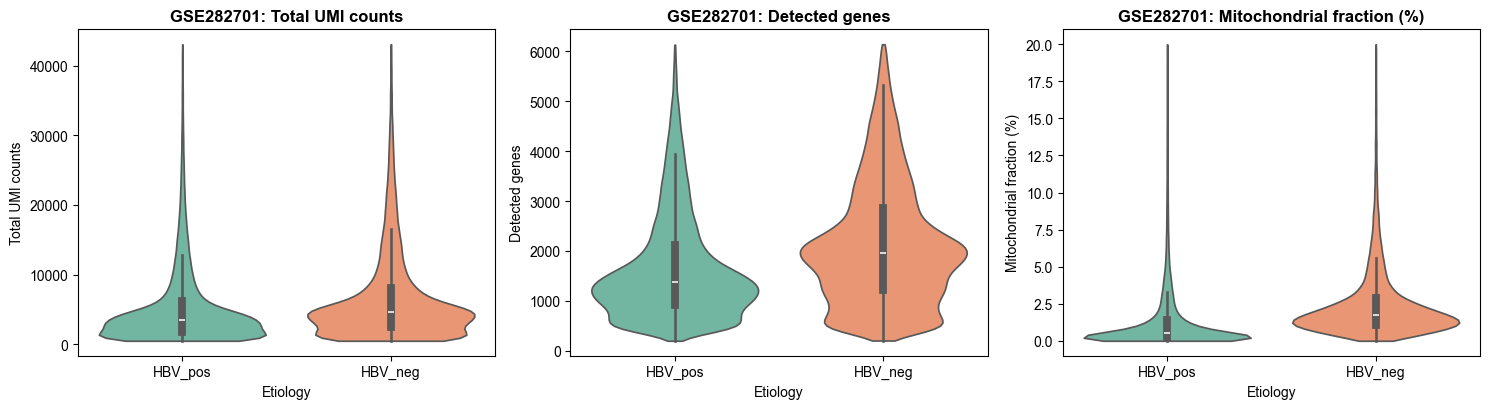

In [ ]:
MIN_GENES = 200
MAX_MT_PCT = 20.0
UPPER_QUANTILE = 0.995

adata.var["mt"] = adata.var_names.str.upper().str.startswith("MT-")
sc.pp.calculate_qc_metrics(adata, qc_vars=["mt"], inplace=True)

upper_genes = np.quantile(adata.obs["n_genes_by_counts"], UPPER_QUANTILE)
upper_counts = np.quantile(adata.obs["total_counts"], UPPER_QUANTILE)

n_raw_cells = adata.n_obs
qc_mask = (
    (adata.obs["n_genes_by_counts"] >= MIN_GENES) &
    (adata.obs["n_genes_by_counts"] <= upper_genes) &
    (adata.obs["total_counts"] <= upper_counts) &
    (adata.obs["pct_counts_mt"] <= MAX_MT_PCT)
)

adata = adata[qc_mask].copy()
sc.pp.filter_genes(adata, min_cells=3)
adata.layers["counts"] = adata.X.copy()

print(f"QC SUMMARY: Retained {adata.n_obs:,} / {n_raw_cells:,} cells ({100*adata.n_obs/n_raw_cells:.2f}%) and {adata.n_vars:,} genes.")


fig, axes = plt.subplots(1, 3, figsize=(15, 4.2))
qc_metrics_plot = [
    ("total_counts", "Total UMI counts"),
    ("n_genes_by_counts", "Detected genes"),
    ("pct_counts_mt", "Mitochondrial fraction (%)")
]
for ax, (col, title) in zip(axes, qc_metrics_plot):
    sns.violinplot(
        data=adata.obs, x="etiology", y=col, 
        order=["HBV_pos", "HBV_neg"],
        palette="Set2", inner="box", cut=0, ax=ax
    )
    ax.set_title(f"{DATASET_ID}: {title}", fontweight="bold")
    ax.set_xlabel("Etiology")
    ax.set_ylabel(title)

In [6]:
adata.obs["doublet_score"] = 0.0
adata.obs["predicted_doublet"] = False

for sid in adata.obs["sample_id"].unique():
    mask = (adata.obs["sample_id"] == sid).values
    X_sub = adata[mask].layers["counts"]
    n_c = X_sub.shape[0]

    exp_rate = float(np.clip(n_c * 0.008 / 1000.0, 0.01, 0.10))
    
    scrub = scr.Scrublet(X_sub, expected_doublet_rate=exp_rate, random_state=RANDOM_STATE)
    scores, preds = scrub.scrub_doublets(
        min_counts=2, min_cells=3, min_gene_variability_pctl=85,
        n_prin_comps=min(30, n_c - 1), verbose=False
    )
    if preds is None or np.mean(preds) < (0.25 * exp_rate):
        thr = np.quantile(scores, 1.0 - exp_rate)
        preds = scores >= thr
        
    adata.obs.loc[mask, "doublet_score"] = scores
    adata.obs.loc[mask, "predicted_doublet"] = preds
    print(f"sample {sid} ({n_c} cells): finding {int(preds.sum())} doublets ({100*np.mean(preds):.2f}%)")

n_before_scrub = adata.n_obs
adata = adata[~adata.obs["predicted_doublet"]].copy()
adata.layers["counts"] = adata.X.copy()
print(f"SCRUBLET: remove {n_before_scrub - adata.n_obs} / {n_before_scrub} cells ({100*(n_before_scrub - adata.n_obs)/n_before_scrub:.2f}%)")
print(f"Remaining clean cells: {adata.n_obs:,} cells × {adata.n_vars:,} genes")

adata.write_h5ad(os.path.join(OUT_DIR, f"{DATASET_ID}_QC.h5ad"))

sample GSM8649020 (18015 cells): finding 1837 doublets (10.20%)
sample GSM8649021 (10846 cells): finding 457 doublets (4.21%)
sample GSM8649022 (9769 cells): finding 338 doublets (3.46%)
sample GSM8649023 (10645 cells): finding 442 doublets (4.15%)
sample GSM8649024 (11978 cells): finding 1174 doublets (9.80%)
sample GSM8649025 (11382 cells): finding 1082 doublets (9.51%)
sample GSM8649026 (12208 cells): finding 1291 doublets (10.58%)
sample GSM8649027 (10702 cells): finding 351 doublets (3.28%)
sample GSM8649028 (9309 cells): finding 720 doublets (7.73%)
sample GSM8649029 (10801 cells): finding 1012 doublets (9.37%)
sample GSM8649030 (10613 cells): finding 256 doublets (2.41%)
sample GSM8649031 (9410 cells): finding 751 doublets (7.98%)
SCRUBLET: remove 9711 / 135678 cells (7.16%)
Remaining clean cells: 125,967 cells × 32,162 genes


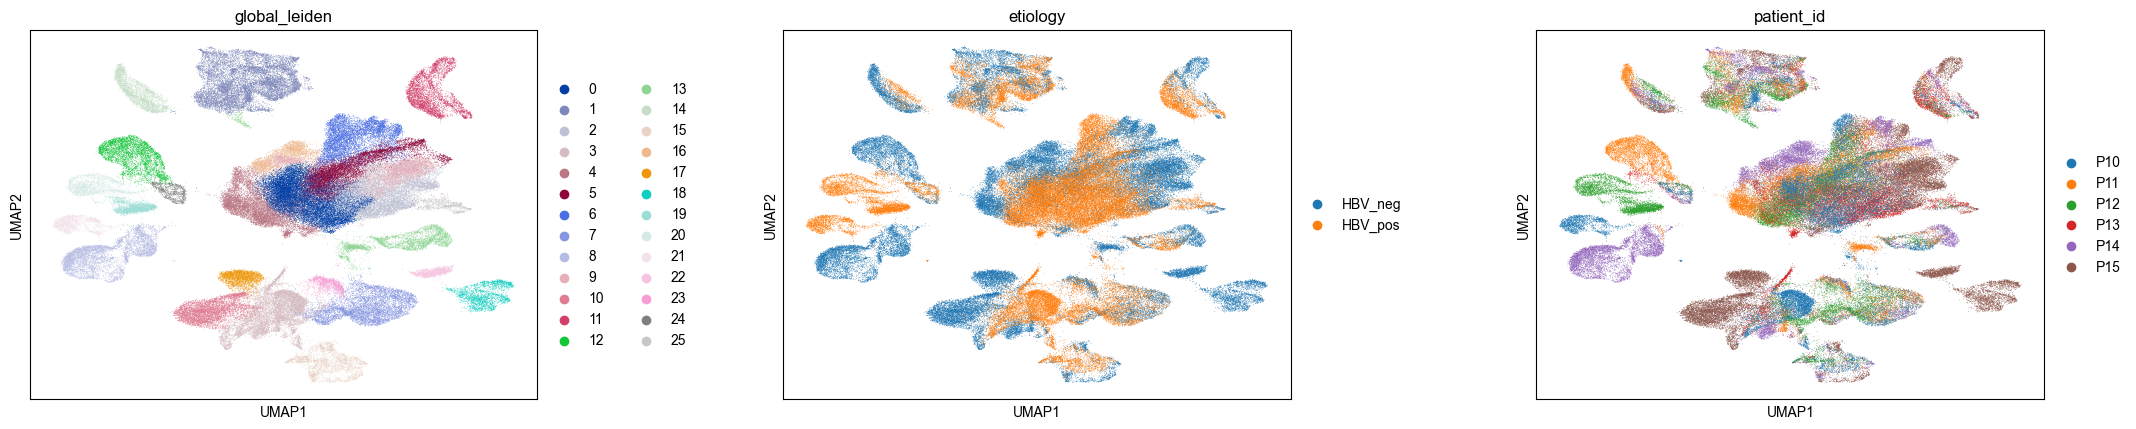

In [ ]:
adata.X = adata.layers["counts"].copy()
sc.pp.normalize_total(adata, target_sum=1e4)
sc.pp.log1p(adata)
adata.layers["log1p_norm"] = adata.X.copy()

sc.pp.highly_variable_genes(
    adata, n_top_genes=3000, flavor="seurat", batch_key="batch", subset=False
)

adata_hvg = adata[:, adata.var["highly_variable"]].copy()
sc.pp.scale(adata_hvg, max_value=10)
sc.tl.pca(adata_hvg, n_comps=40, svd_solver="arpack", random_state=RANDOM_STATE)

adata.obsm["X_pca"] = adata_hvg.obsm["X_pca"].copy()
del adata_hvg
gc.collect()

sc.pp.neighbors(adata, n_neighbors=15, n_pcs=30, random_state=RANDOM_STATE)
sc.tl.umap(adata, random_state=RANDOM_STATE)
sc.tl.leiden(adata, resolution=0.5, key_added="global_leiden", random_state=RANDOM_STATE)

sc.pl.umap(adata, color=["global_leiden", "etiology", "patient_id"],wspace=0.35, show=False)

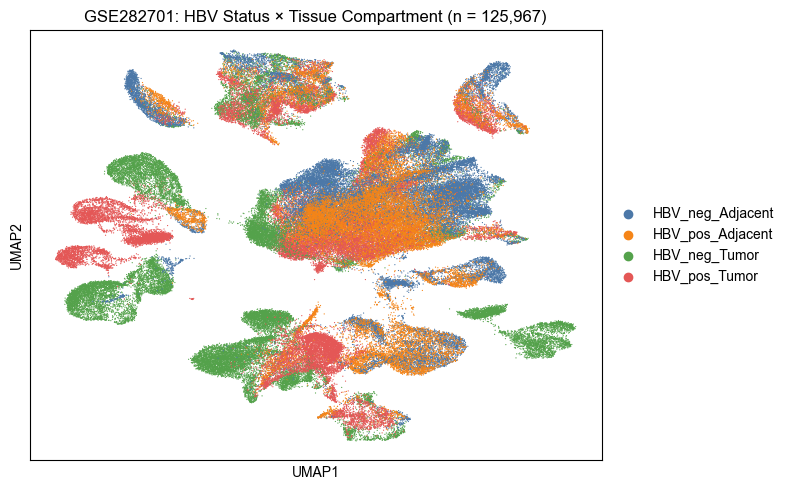

condition_group
HBV_neg_Adjacent    30381
HBV_pos_Adjacent    29310
HBV_neg_Tumor       34198
HBV_pos_Tumor       32078
Name: count, dtype: int64


In [ ]:
groups = ["HBV_neg_Adjacent", "HBV_pos_Adjacent", "HBV_neg_Tumor", "HBV_pos_Tumor"]
adata.obs["condition_group"] = pd.Categorical(
    adata.obs["etiology"].astype(str) + "_" + adata.obs["tissue"].astype(str),
    categories=groups, ordered=True
)
fig, ax = plt.subplots(figsize=(8, 5))
sc.pl.umap(
    adata, color="condition_group", palette=["#4C78A8", "#F58518", "#54A24B", "#E45756"],
    size=3, frameon=True, legend_loc="right margin", ax=ax, show=False,
    title=f"{DATASET_ID}: HBV Status × Tissue Compartment (n = {adata.n_obs:,})"
)
print(adata.obs["condition_group"].value_counts().reindex(groups, fill_value=0))


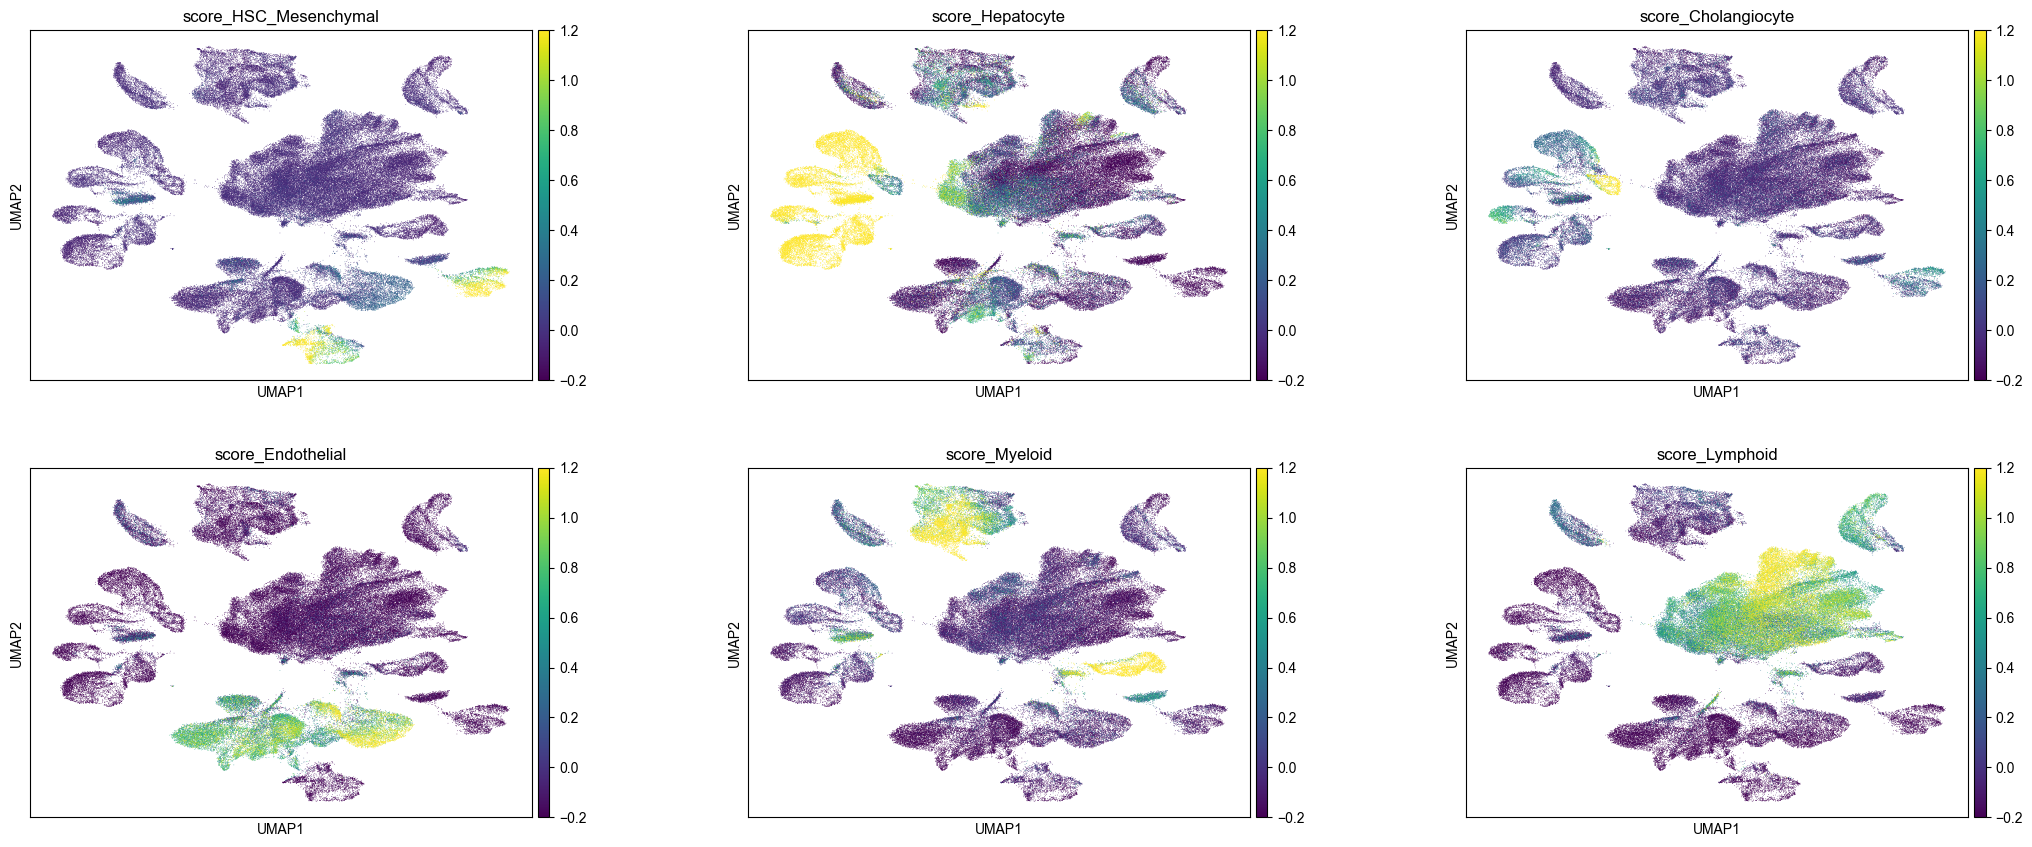

Selected Mesenchymal Leiden clusters: ['15', '18']
Extracted Mesenchymal compartment: 4,982 / 125,967 cells (3.96%)


In [ ]:
GLOBAL_LINEAGE_PANELS = {
    "HSC_Mesenchymal": ["PDGFRB", "DCN", "RGS5", "ECM1", "RELN", "DES", "LRAT", "CYGB", "COL1A2","COL1A1","COL3A1", "LUM"],
    "Hepatocyte": ["ALB", "CPS1", "APOA1", "APOA2", "CYP3A4", "HNF4A"],
    "Cholangiocyte": ["EPCAM", "KRT19", "KRT7", "SOX9", "ANXA4"],
    "Endothelial": ["PECAM1", "KDR", "VWF", "STAB2", "CLDN5", "FCN2"],
    "Myeloid": ["CD68", "MARCO", "CD163", "LYZ", "C1QA", "VSIG4"],
    "Lymphoid": ["PTPRC", "CD3D", "CD3E", "NKG7", "GNLY", "CD79A", "MS4A1"]
}

score_cols = []
for lin_name, markers in GLOBAL_LINEAGE_PANELS.items():
    present = [g for g in markers if g in adata.var_names]
    col_name = f"score_{lin_name}"
    sc.tl.score_genes(adata, gene_list=present, score_name=col_name, use_raw=False)
    score_cols.append(col_name)

z_cols = [f"z_{c}" for c in score_cols]
adata.obs[z_cols] = StandardScaler().fit_transform(adata.obs[score_cols])

sc.pl.umap(
    adata, color=score_cols, cmap="viridis", 
    ncols=3, wspace=0.3, vmin=-0.2, vmax=1.2, show=False)

cluster_z = adata.obs.groupby("global_leiden")[z_cols].mean()
non_mes_z_cols = [c for c in z_cols if c != "z_score_HSC_Mesenchymal"]
cluster_z["max_non_mes_z"] = cluster_z[non_mes_z_cols].max(axis=1)

mes_clusters = cluster_z.index[
    (cluster_z["z_score_HSC_Mesenchymal"] > 1.0) &
    (cluster_z["z_score_HSC_Mesenchymal"] > cluster_z["max_non_mes_z"] + 0.3)
].tolist()

if len(mes_clusters) == 0:
    mes_clusters = cluster_z.index[
        (cluster_z["z_score_HSC_Mesenchymal"] > 0.7) &
        (cluster_z["z_score_HSC_Mesenchymal"] > cluster_z["max_non_mes_z"])
    ].tolist()

adata.obs["is_mesenchymal_compartment"] = adata.obs["global_leiden"].isin(mes_clusters)
adata_mes = adata[adata.obs["is_mesenchymal_compartment"]].copy()

print(f"Selected Mesenchymal Leiden clusters: {mes_clusters}")
print(f"Extracted Mesenchymal compartment: {adata_mes.n_obs:,} / {adata.n_obs:,} cells ({100*adata_mes.n_obs/adata.n_obs:.2f}%)")

mes_lineage_class
HSC                   3142
VSMC_Pericyte          742
Contam_Mesothelial     575
Portal_Fibroblast      523
Name: count, dtype: int64
---------------------------------------------------------------------------
[✓] Primary Clean HSCs : 3,142 cells (63.1% Mesenchymal, 2.49% Whole Liver)
    • Inclusive HSCs   : 4,409 cells
    • Stringent HSCs   : 2,194 cells


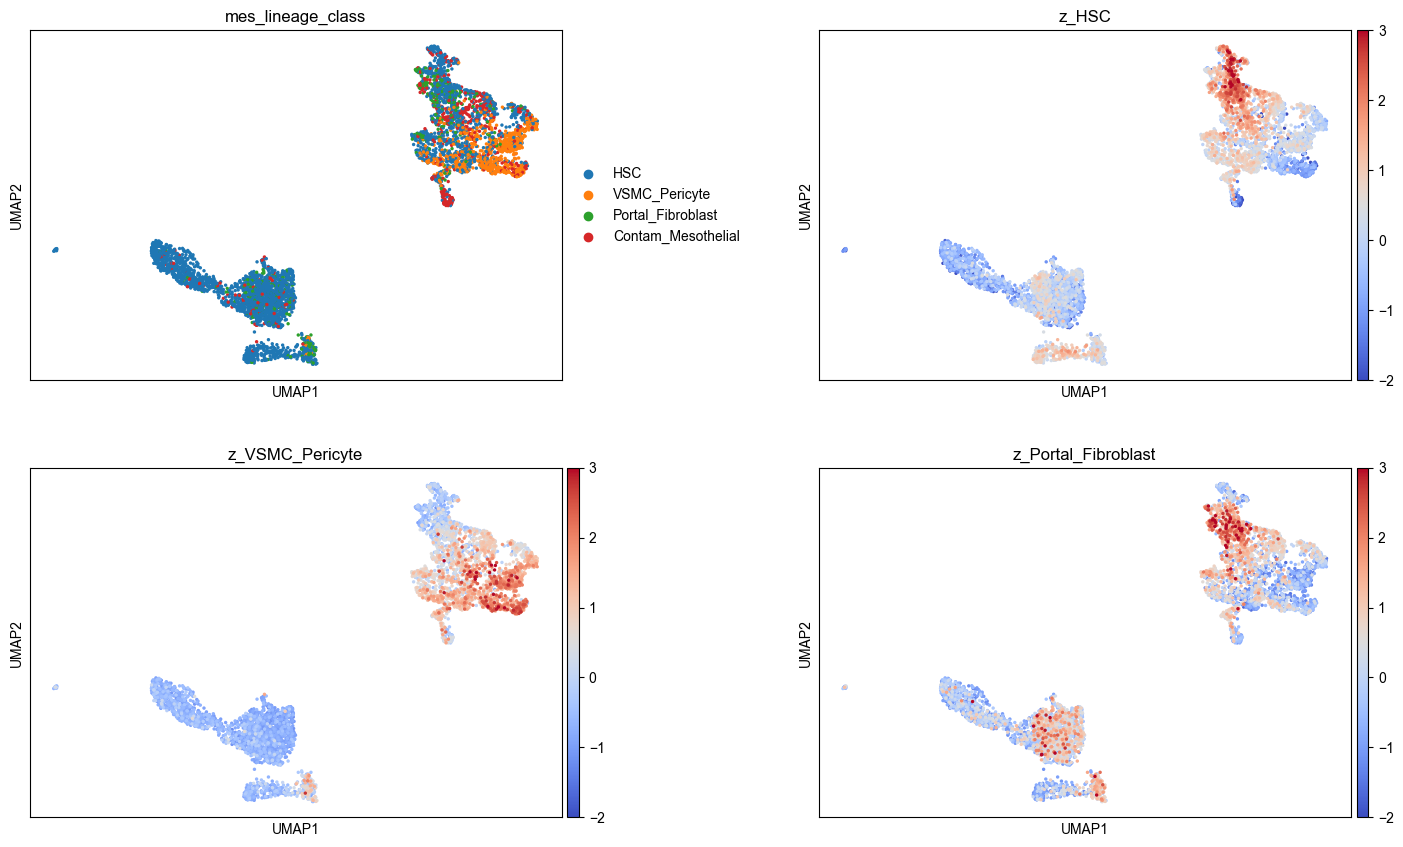

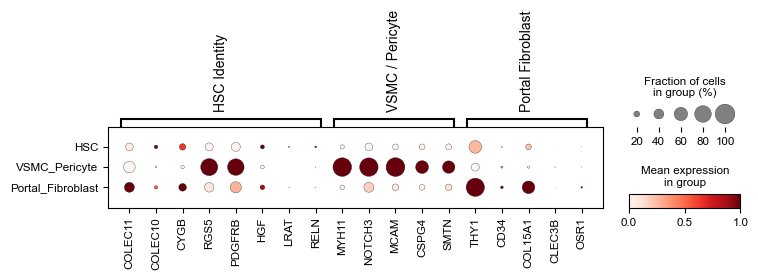

In [ ]:
adata_mes.X = adata_mes.layers["log1p_norm"].copy()
sc.pp.highly_variable_genes(adata_mes, n_top_genes=2000, flavor="seurat", subset=False)

adata_mes_hvg = adata_mes[:, adata_mes.var["highly_variable"]].copy()
sc.pp.scale(adata_mes_hvg, max_value=10)
sc.tl.pca(adata_mes_hvg, n_comps=25, svd_solver="arpack", random_state=RANDOM_STATE)
adata_mes.obsm["X_pca"] = adata_mes_hvg.obsm["X_pca"].copy()
del adata_mes_hvg

sc.pp.neighbors(adata_mes, n_neighbors=15, n_pcs=20, random_state=RANDOM_STATE)
sc.tl.umap(adata_mes, random_state=RANDOM_STATE)
sc.tl.leiden(adata_mes, resolution=0.8, key_added="mes_subcluster", random_state=RANDOM_STATE)

PANELS_GATING = {
    "HSC_Core": [
        "LRAT", "RBP1", "CYGB", "RELN", "COLEC11", "COLEC10", "ACTA2",  
        "DCN", "LUM", "COL1A1", "COL1A2", "COL3A1", "RGS5", "CNN1",
        "DES", "GFAP", "PDGFRB", "SPARC", "IGFBP3","TIMP1","TAGLN"
    ],
    "VSMC_Pericyte": [
        "MYH11", "NOTCH3", "CSPG4", "MCAM", "SMTN", "MYLK"
    ],
    "Portal_Fibroblast": [
        "CLEC3B", "CD34", "COL15A1", "THY1", "OSR1", "MFAP4"
    ],
    "Mesothelial": [
        "UPK3B", "MSLN", "UPK1B"
    ],
    "Lineage_Contam": [
        "PTPRC", "LYZ", "CD68", "PECAM1", "VWF", "KDR", "ALB", "EPCAM", "TTR"
    ]
}

for p_name, p_genes in PANELS_GATING.items():
    valid_g = [g for g in p_genes if g in adata_mes.var_names]
    sc.tl.score_genes(
        adata_mes, gene_list=valid_g, score_name=f"score_{p_name}", 
        random_state=RANDOM_STATE, use_raw=False
    )

def calc_zscore(series):
    sd = series.std(ddof=0)
    return (series - series.mean()) / (sd if sd > 0 else 1.0)

adata_mes.obs["z_HSC"]               = calc_zscore(adata_mes.obs["score_HSC_Core"])
adata_mes.obs["z_VSMC_Pericyte"]     = calc_zscore(adata_mes.obs["score_VSMC_Pericyte"])
adata_mes.obs["z_Portal_Fibroblast"] = calc_zscore(adata_mes.obs["score_Portal_Fibroblast"])
adata_mes.obs["z_Mesothelial"]       = calc_zscore(adata_mes.obs["score_Mesothelial"])
adata_mes.obs["z_Lineage_Contam"]    = calc_zscore(adata_mes.obs["score_Lineage_Contam"])

z_hsc    = adata_mes.obs["z_HSC"]
z_vsmc   = adata_mes.obs["z_VSMC_Pericyte"]
z_pf     = adata_mes.obs["z_Portal_Fibroblast"]
z_meso   = adata_mes.obs["z_Mesothelial"]
z_contam = adata_mes.obs["z_Lineage_Contam"]

raw_X = adata_mes.layers["counts"]
gene_to_idx = {g: i for i, g in enumerate(adata_mes.var_names)}
def get_raw_count(g):
    return raw_X[:, gene_to_idx[g]].toarray().ravel() if g in gene_to_idx else np.zeros(adata_mes.n_obs)

is_vsmc_leak  = (z_vsmc > 1.0) & (z_vsmc > z_hsc)
is_pf_leak    = (z_pf > 1.0) & (z_pf > z_hsc)
is_meso_leak  = (z_meso > 1.5) & (z_meso > z_hsc)
is_other_leak = (z_contam > 1.8) | (get_raw_count("PTPRC") > 0) | (get_raw_count("EPCAM") > 0)

mes_class = pd.Series("HSC", index=adata_mes.obs_names)
mes_class.loc[is_vsmc_leak]  = "VSMC_Pericyte"
mes_class.loc[is_pf_leak]    = "Portal_Fibroblast"
mes_class.loc[is_meso_leak | is_other_leak] = "Contam_Mesothelial"
adata_mes.obs["mes_lineage_class"] = pd.Categorical(
    mes_class, categories=["HSC", "VSMC_Pericyte", "Portal_Fibroblast", "Contam_Mesothelial"]
)

hsc_clean_bool = (adata_mes.obs["mes_lineage_class"] == "HSC")
adata_mes.obs["is_HSC_clean"]     = hsc_clean_bool.values
adata_mes.obs["is_HSC_primary"]   = hsc_clean_bool.values
adata_mes.obs["is_HSC_inclusive"] = (~is_other_leak).values
adata_mes.obs["is_HSC_stringent"] = (hsc_clean_bool & (z_vsmc < 0.5) & (z_pf < 0.5)).values

n_clean = int(adata_mes.obs["is_HSC_clean"].sum())
n_mes   = adata_mes.n_obs
print("=" * 75)
print(adata_mes.obs["mes_lineage_class"].value_counts())
print("-" * 75)
print(f"[✓] Primary Clean HSCs : {n_clean:,} cells ({100*n_clean/n_mes:.1f}% Mesenchymal, {100*n_clean/adata.n_obs:.2f}% Whole Liver)")
print(f"    • Inclusive HSCs   : {int(adata_mes.obs['is_HSC_inclusive'].sum()):,} cells")
print(f"    • Stringent HSCs   : {int(adata_mes.obs['is_HSC_stringent'].sum()):,} cells")
print("=" * 75)

sc.pl.umap(
    adata_mes, 
    color=["mes_lineage_class", "z_HSC", "z_VSMC_Pericyte", "z_Portal_Fibroblast"],
    ncols=2, wspace=0.35, cmap="coolwarm", vmin=-2.0, vmax=3.0, show=False)

adata_mes_plot = adata_mes[adata_mes.obs["mes_lineage_class"].isin(["HSC", "VSMC_Pericyte", "Portal_Fibroblast"])].copy()
lineage_dotplot_dict = {
    "HSC Identity":      [g for g in ["COLEC11", "COLEC10", "CYGB", "RGS5", "PDGFRB", "HGF", "LRAT", "RELN"] if g in adata_mes_plot.var_names],
    "VSMC / Pericyte":   [g for g in ["MYH11", "NOTCH3", "MCAM", "CSPG4", "SMTN"] if g in adata_mes_plot.var_names],
    "Portal Fibroblast": [g for g in ["THY1", "CD34", "COL15A1", "CLEC3B", "OSR1"] if g in adata_mes_plot.var_names]
}
sc.pl.dotplot(
    adata_mes_plot, var_names=lineage_dotplot_dict, groupby="mes_lineage_class",
    standard_scale="var", cmap="Reds", show=False)

In [ ]:
adata_hsc = adata_mes[adata_mes.obs["is_HSC_clean"]].copy()
adata_hsc.X = adata_hsc.layers["log1p_norm"].copy()

HSC_STATE_PANELS = {
    "qHSC": [
        "LRAT", "RBP1", "RELN", "CYGB", "COLEC11", "COLEC10", 
        "VIPR1", "HHIP", "NGFR", "GFAP", "PPARG", "ADGRL3"
    ],
    "A1_HSC": [
        "ACTA2", "TAGLN", "MYL9", "TPM2", "CNN1", "CALD1", "MYLK", "VCL"
    ],
    "A2_HSC": [
        "COL1A1", "COL1A2", "COL3A1", "LUM", "TIMP1", "SERPINE1", 
        "SPARC", "FN1", "VCAN", "POSTN", "LOXL2", "MMP2"
    ],
    "INF_HSC": [
        "CCL2", "CXCL8", "CXCL1", "CXCL2", "IL6", "ICAM1", 
        "NFKBIA", "TNFAIP3", "CCL20", "SOD2", "IRF1"
    ]
}

sc.pp.highly_variable_genes(adata_hsc, n_top_genes=1500, flavor="seurat", subset=False)
adata_hsc_hvg = adata_hsc[:, adata_hsc.var["highly_variable"]].copy()
sc.pp.scale(adata_hsc_hvg, max_value=10)
sc.tl.pca(adata_hsc_hvg, n_comps=20, svd_solver="arpack", random_state=RANDOM_STATE)
adata_hsc.obsm["X_pca"] = adata_hsc_hvg.obsm["X_pca"].copy()
del adata_hsc_hvg

sc.pp.neighbors(adata_hsc, n_neighbors=15, n_pcs=15, random_state=RANDOM_STATE)
sc.tl.umap(adata_hsc, min_dist=0.3, random_state=RANDOM_STATE)
sc.tl.leiden(adata_hsc, resolution=0.6, key_added="hsc_leiden", random_state=RANDOM_STATE)

raw_state_cols = []
for st_name, genes in HSC_STATE_PANELS.items():
    valid_g = [g for g in genes if g in adata_hsc.var_names]
    col = f"score_{st_name}"
    sc.tl.score_genes(adata_hsc, gene_list=valid_g, score_name=col, use_raw=False, ctrl_size=50, random_state=RANDOM_STATE)
    raw_state_cols.append(col)

z_state_cols = ["qHSC", "A1_HSC", "A2_HSC", "INF_HSC"]
Z_raw = StandardScaler().fit_transform(adata_hsc.obs[raw_state_cols].values)

conn = adata_hsc.obsp["connectivities"].copy()
row_sums = np.array(conn.sum(axis=1)).ravel()
row_sums[row_sums == 0] = 1.0
W = sp.diags(1.0 / row_sums) @ conn
Z_smoothed = 0.70 * Z_raw + 0.30 * (W @ Z_raw)

adata_hsc.obs[z_state_cols] = Z_smoothed
adata_hsc.obs["HSC_state"] = adata_hsc.obs[z_state_cols].idxmax(axis=1)
adata_hsc.obs["HSC_state"] = pd.Categorical(
    adata_hsc.obs["HSC_state"], categories=["qHSC", "A1_HSC", "A2_HSC", "INF_HSC"], ordered=True
)

print("=" * 75)
print(f"4 STATES ({DATASET_ID}: n = {adata_hsc.n_obs:,} cells) ===")
state_counts = adata_hsc.obs["HSC_state"].value_counts()
for st in ["qHSC", "A1_HSC", "A2_HSC", "INF_HSC"]:
    cnt = state_counts.get(st, 0)
    print(f"  • {st:<8}: {cnt:>4} cells ({100*cnt/adata_hsc.n_obs:>5.2f}%)")

print("\n ETIOLOGY × HSC STATE (cell counts) ")
ct_counts = pd.crosstab(adata_hsc.obs["etiology"], adata_hsc.obs["HSC_state"], margins=True)
print(ct_counts)

print("\n Etiology-based percentage of 4 states (%) ")
ct_pct = pd.crosstab(adata_hsc.obs["etiology"], adata_hsc.obs["HSC_state"], normalize="index") * 100
ct_pct = ct_pct.reindex([e for e in ["HBV_pos", "HBV_neg"] if e in ct_pct.index])
print(ct_pct.round(2))

donor_audit = pd.crosstab(
    [adata_hsc.obs["etiology"], adata_hsc.obs["patient_id"]], 
    adata_hsc.obs["HSC_state"], margins=True, margins_name="Total_HSCs"
)
donor_audit.to_csv(os.path.join(OUT_DIR, f"{DATASET_ID}_Donor_Level_HSC_Audit.csv"))
print("\n DONOR-LEVEL REPLICATES ")
print(donor_audit)
print("=" * 75)

4 STATES (GSE282701: n = 3,142 cells) ===
  • qHSC    :  418 cells (13.30%)
  • A1_HSC  :  651 cells (20.72%)
  • A2_HSC  : 1297 cells (41.28%)
  • INF_HSC :  776 cells (24.70%)

 ETIOLOGY × HSC STATE (cell counts) 
HSC_state  qHSC  A1_HSC  A2_HSC  INF_HSC   All
etiology                                      
HBV_neg     180     209    1265      688  2342
HBV_pos     238     442      32       88   800
All         418     651    1297      776  3142

 Etiology-based percentage of 4 states (%) 
HSC_state   qHSC  A1_HSC  A2_HSC  INF_HSC
etiology                                 
HBV_pos    29.75   55.25    4.00    11.00
HBV_neg     7.69    8.92   54.01    29.38

 DONOR-LEVEL REPLICATES 
HSC_state              qHSC  A1_HSC  A2_HSC  INF_HSC  Total_HSCs
etiology   patient_id                                           
HBV_neg    P11           12      21       0        4          37
           P14           66      59       9        5         139
           P15          102     129    1256      6

HSC counts by group:
 condition_group
HBV_neg_Adjacent      83
HBV_pos_Adjacent     181
HBV_neg_Tumor       2259
HBV_pos_Tumor        619
HSC state composition (%):
 HSC_state          qHSC  A1_HSC  A2_HSC  INF_HSC
condition_group                                 
HBV_neg_Adjacent  54.22   33.73    0.00    12.05
HBV_pos_Adjacent  76.80   20.44    0.00     2.76
HBV_neg_Tumor      5.98    8.01   56.00    30.01
HBV_pos_Tumor     15.99   65.43    5.17    13.41


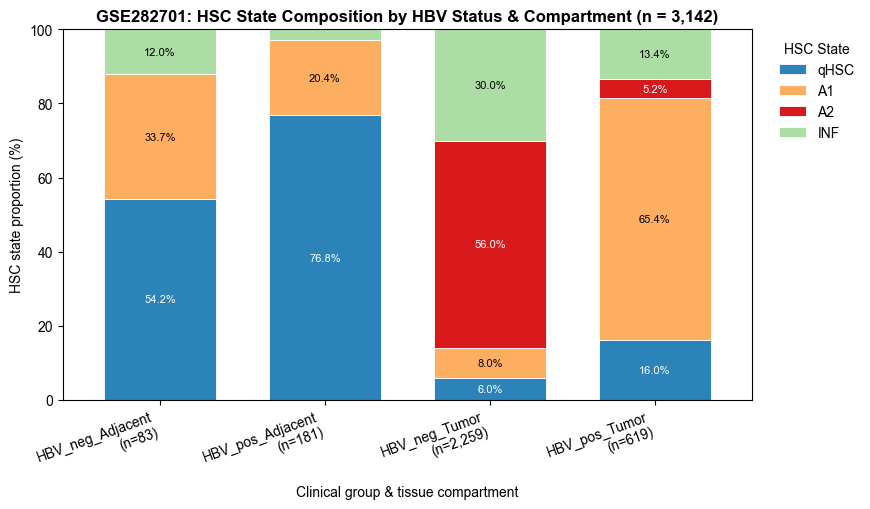

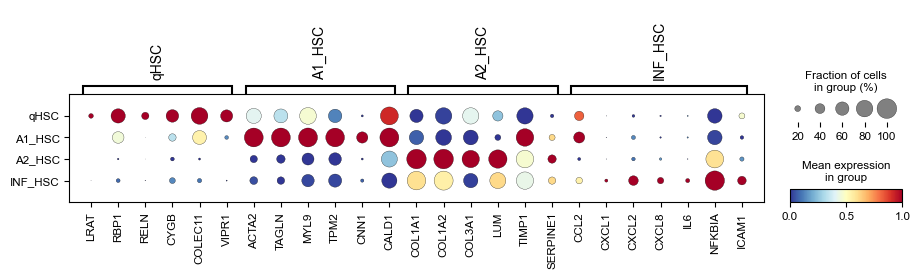

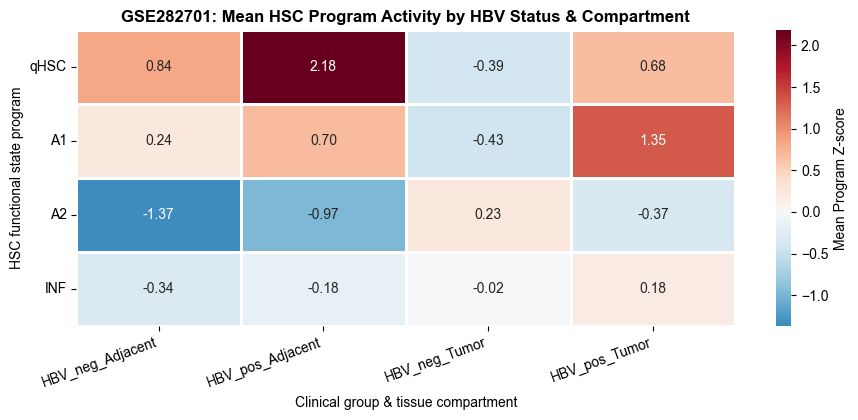

In [ ]:
state_palette = {"qHSC": "#2b83ba", "A1_HSC": "#fdae61", "A2_HSC": "#d7191c", "INF_HSC": "#abdda4"}
states_282701 = list(state_palette)
order_282701 = ["HBV_neg_Adjacent", "HBV_pos_Adjacent", "HBV_neg_Tumor", "HBV_pos_Tumor"]

adata_hsc.obs["condition_group"] = (adata_hsc.obs["etiology"].astype(str) + "_" + adata_hsc.obs["tissue"].astype(str))
counts_282701 = pd.crosstab(adata_hsc.obs["condition_group"], adata_hsc.obs["HSC_state"]).reindex(
    index=order_282701, columns=states_282701, fill_value=0
)
comp_282701 = counts_282701.div(counts_282701.sum(axis=1).replace(0, np.nan), axis=0).mul(100).fillna(0)

fig, ax = plt.subplots(figsize=(8.8, 5.2))
comp_282701.rename(columns={"A1_HSC": "A1", "A2_HSC": "A2", "INF_HSC": "INF"}).plot(
    kind="bar", stacked=True, ax=ax, color=list(state_palette.values()),
    edgecolor="white", linewidth=0.6, width=0.68
)
for container, text_color in zip(ax.containers, ["white", "black", "white", "black"]):
    ax.bar_label(container, labels=[f"{v:.1f}%" if v >= 4 else "" for v in container.datavalues],
                 label_type="center", fontsize=8, color=text_color)
ax.set(ylim=(0, 100), xlabel="Clinical group & tissue compartment", ylabel="HSC state proportion (%)")
ax.set_title(f"{DATASET_ID}: HSC State Composition by HBV Status & Compartment (n = {adata_hsc.n_obs:,})", fontweight="bold")
ax.set_xticklabels([f"{g}\n(n={n:,})" for g, n in counts_282701.sum(axis=1).items()], rotation=20, ha="right")
ax.legend(title="HSC State", bbox_to_anchor=(1.02, 1), loc="upper left", frameon=False)
print("HSC counts by group:\n", counts_282701.sum(axis=1).to_string())
print("HSC state composition (%):\n", comp_282701.round(2).to_string())

# Grouped dotplot 
state_marker_dict = {
    "qHSC":    [g for g in ["LRAT", "RBP1", "RELN", "CYGB", "COLEC11", "VIPR1"] if g in adata_hsc.var_names],
    "A1_HSC":  [g for g in ["ACTA2", "TAGLN", "MYL9", "TPM2", "CNN1", "CALD1"] if g in adata_hsc.var_names],
    "A2_HSC":  [g for g in ["COL1A1", "COL1A2", "COL3A1", "LUM", "TIMP1", "SERPINE1"] if g in adata_hsc.var_names],
    "INF_HSC": [g for g in ["CCL2", "CXCL1", "CXCL2", "CXCL8", "IL6", "NFKBIA", "ICAM1"] if g in adata_hsc.var_names]
}
sc.pl.dotplot(adata_hsc, var_names=state_marker_dict, groupby="HSC_state",
              standard_scale="var", cmap="RdYlBu_r", show=False)
# Heatmap
heat_282701 = (adata_hsc.obs.groupby("condition_group")[states_282701].mean()
               .reindex(order_282701).T)
heat_282701.index = ["qHSC", "A1", "A2", "INF"]
fig, ax = plt.subplots(figsize=(9.2, 4.3))
sns.heatmap(heat_282701, annot=True, fmt=".2f", cmap="RdBu_r", center=0,
            linewidths=0.8, cbar_kws={"label": "Mean Program Z-score"}, ax=ax)
ax.set_title(f"{DATASET_ID}: Mean HSC Program Activity by HBV Status & Compartment", fontweight="bold")
ax.set(xlabel="Clinical group & tissue compartment", ylabel="HSC functional state program")
ax.set_xticklabels(ax.get_xticklabels(), rotation=20, ha="right")
ax.set_yticklabels(ax.get_yticklabels(), rotation=0)

adata_hsc.X = adata_hsc.layers["counts"].copy()
out_h5ad = os.path.join(OUT_DIR, f"{DATASET_ID}_HSC_clean.h5ad")
adata_hsc.write_h5ad(out_h5ad)